# Copper price prediction — LSTM baseline vs SA-LSTM tối ưu lại 2006–2026 vs SA-LSTM bài báo

**Đối chiếu:** Chen et al. (2023), *PLOS ONE*, DOI: https://doi.org/10.1371/journal.pone.0285631.

**Dữ liệu:** Yahoo Finance 2006-01-01 đến 2026-11-01 (khác dữ liệu Investing.com 1990–2009 tác giả sử dụng). Tải **giá đồng + 8 biến ứng viên**, lưu CSV → chia tập theo thời gian → Spearman chỉ trên fit/train → fit scaler chỉ trên fit/train → tạo sequences → huấn luyện và đánh giá ba mô hình qua các tỷ lệ 90/10, 92.5/7.5, 95/5.

**3 cấu hình so sánh:**
1. LSTM baseline 32/32, learning rate 1e-3, cố định, không tối ưu (lựa chọn của đồ án).
2. SA-LSTM *do bạn tự chạy SA*: 39/111, learning rate 5e-5 (mặc định giữ kết quả cũ; tùy chọn rerun SA).
3. SA-LSTM *tác giả công bố Table 4*: 39/111, learning rate 5e-5.

**Quan trọng:** Hai cấu hình SA trùng nhau nên với cùng seed và đầu vào sẽ cho kết quả giống nhau; không được diễn giải đó là hai hiệu năng độc lập. Bài báo công bố 39/111 trong Table 4, trang 15. Việc dùng `Dense(1, activation='tanh')` là **thử nghiệm riêng theo yêu cầu**, không phải thông số tác giả xác nhận; tanh có miền giá trị [-1,1] và có thể kém phù hợp với target chuẩn hóa [0,1]. Dense(32, relu) là giả định triển khai vì bài báo không nêu rõ activation Dense.

Không sử dụng BA/SVR/ANFIS để train; chỉ ghi dẫn nguồn [26]–[28] và không ngụy tạo MSE. Notebook chỉ kiểm tra được cú pháp tĩnh tại đây, không xác nhận train toàn bộ trên GPU Kaggle.

In [16]:
# Không ép cài lại curl_cffi: Kaggle đã xác nhận tải thành công bằng subprocess.
# Nếu cần: %pip install -q yfinance pandas numpy scikit-learn matplotlib

In [17]:
import sys
import subprocess

code = """
import curl_cffi
from curl_cffi import requests

print("curl_cffi:", curl_cffi.__version__)
print("Path:", curl_cffi.__file__)

for browser in ["chrome", "chrome136", "chrome124"]:
    try:
        r = requests.get(
            "https://www.google.com",
            impersonate=browser,
            timeout=15
        )
        print(browser, "OK", r.status_code)
    except Exception as e:
        print(browser, "FAILED", type(e).__name__, str(e))
"""

result = subprocess.run(
    [sys.executable, "-c", code],
    capture_output=True,
    text=True,
    timeout=90
)

print(result.stdout)
print(result.stderr[-2000:])

curl_cffi: 0.16.3
Path: /usr/local/lib/python3.13/dist-packages/curl_cffi/__init__.py
chrome OK 200
chrome136 OK 200
chrome124 OK 200




In [18]:
import os, random, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
try: tf.config.experimental.enable_op_determinism()
except Exception: pass
START, END_EXCLUSIVE = '2006-01-01', '2026-11-02'
SEQ_LENGTH = 30
TRAIN_RATIOS = [0.90, 0.925, 0.95]
EPOCHS = 100
BATCH = 64
SA_MODE = 'rerun'  # MẶC ĐỊNH: tối ưu lại SA theo dữ liệu hiện tại, CHỈ dùng train/validation
SA_STEPS = 30       # 30 đề xuất/ratio; tăng lên 50+ nếu GPU/ thời gian cho phép
SA_TRIAL_EPOCHS = 15  # tìm kiếm nhanh, sau đó train lại 100 epochs với bộ tốt nhất
SA_INIT = {'lr': 0.0005, 'units1': 15, 'units2': 30}  # khởi tạo SA theo bài báo, KHÔNG dùng kết quả 39/111
SA_T0 = 1.0
SA_COOLING = 0.95
SPEARMAN_CUTOFF = 0.80    # bài báo dùng >0.8 (tương quan dương)
PAPER_FEATURES = ['WTI','Gold','Silver']
# Nếu dữ liệu mới không còn chỉ báo nào >0.8, chọn top 3 dựa trên TRAIN và ghi rõ là thích nghi
print('TensorFlow:', tf.__version__, '| yfinance:', yf.__version__)

TensorFlow: 2.21.0 | yfinance: 0.2.66


## 1. Dữ liệu — 8 chỉ báo của Table 1 và target

Dow Jones, Nasdaq, Dollar Index, US Treasury 10Y yield, Gold, Silver, WTI Oil, **Copper Volume**; target: **Copper Close**. `^TNX` thường đã được Yahoo niêm yết theo %, chỉ chia 10 nếu dữ liệu ở thang 10×. Dùng **inner join theo ngày** và xóa ngày có dữ liệu khuyết, đúng quy tắc bài báo. Đóng cửa hợp đồng tương lai Yahoo là proxy, không hoàn toàn đồng nhất chuỗi lịch sử Investing.

In [19]:
TICKERS = {
    'Copper': ['HG=F'], 'Dow_Jones':['^DJI'], 'Nasdaq':['^IXIC'],
    'Dollar_Index':['DX-Y.NYB','DX=F'], 'TBill_10Y':['^TNX'],
    'Gold':['GC=F'], 'Silver':['SI=F'], 'WTI':['CL=F']
}

import subprocess
import sys
import pandas as pd

def fetch_one(ticker):
    code = """
import yfinance as yf
import sys

df = yf.download(
    sys.argv[1],
    start=sys.argv[3],
    end=sys.argv[4],
    auto_adjust=False,
    progress=False,
    threads=False
)

if df.empty:
    raise RuntimeError(f"Yahoo returned empty data: {sys.argv[1]}")

df.to_pickle(sys.argv[2])
"""

    import tempfile
    import os

    with tempfile.TemporaryDirectory() as tmp:
        path = os.path.join(tmp, "data.pkl")

        subprocess.run(
            [sys.executable, "-c", code, ticker, path, START, END_EXCLUSIVE],
            check=True,
            timeout=120
        )

        df = pd.read_pickle(path)

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    return df

sources = {}; series = {}
for name, candidates in TICKERS.items():
    last_err = None
    for ticker in candidates:
        try:
            frame = fetch_one(ticker)
            if frame['Close'].notna().sum() < 1000:
                raise ValueError(f'Không đủ lịch sử cho {ticker}')
            sources[name] = ticker
            series[name] = pd.to_numeric(frame['Close'], errors='coerce').rename(name)
            if name == 'Copper':
                series['Copper_Volume'] = pd.to_numeric(frame['Volume'], errors='coerce').rename('Copper_Volume')
            print(f'{name:15s} {ticker:10s} {len(frame):5d} rows | {frame.index.min().date()} → {frame.index.max().date()}')
            break
        except Exception as ex:
            last_err = ex
            print(f'WARN {name}: {ticker} không tải được: {str(ex)[:130]}')
    else:
        raise RuntimeError(f'Không lấy được {name}, đã thử {candidates}. Bật Kaggle Internet và Run All lại.') from last_err

raw = pd.concat(series.values(), axis=1, join='inner').sort_index()
raw = raw.loc[(raw.index >= START) & (raw.index < END_EXCLUSIVE)].copy()
# Yahoo ^TNX currently quotes yield directly in % (~4-5), some legacy feeds use 10x.
if raw['TBill_10Y'].median() > 15:
    raw['TBill_10Y'] = raw['TBill_10Y'] / 10.0
missing = raw.isna().sum().rename('missing_rows_before_drop')
print('Missing per column:', missing.to_string())
raw = raw.replace([np.inf,-np.inf], np.nan).dropna(how='any')
raw = raw.loc[~raw.index.duplicated(keep='last')]
assert raw.index.is_monotonic_increasing and raw.index.is_unique
assert len(raw) > 1000, f'Chỉ {len(raw)} phiên hoàn chỉnh; kiểm tra nguồn dữ liệu'
assert len(raw.columns) == 9 and raw.columns.is_unique
print('Dữ liệu hoàn chỉnh:', raw.shape, '→', raw.index.min().date(), raw.index.max().date())
print('Ticker mapping:', sources)
display(raw.head(3)); display(raw.tail(3))

Copper          HG=F        5242 rows | 2006-01-03 → 2026-10-30
Dow_Jones       ^DJI        5240 rows | 2006-01-03 → 2026-10-30
Nasdaq          ^IXIC       5240 rows | 2006-01-03 → 2026-10-30
Dollar_Index    DX-Y.NYB    5243 rows | 2006-01-03 → 2026-10-30
TBill_10Y       ^TNX        5237 rows | 2006-01-03 → 2026-10-30
Gold            GC=F        5240 rows | 2006-01-03 → 2026-10-30
Silver          SI=F        5240 rows | 2006-01-03 → 2026-10-30
WTI             CL=F        5240 rows | 2006-01-03 → 2026-10-30
Missing per column: Copper           0
Copper_Volume    0
Dow_Jones        0
Nasdaq           0
Dollar_Index     0
TBill_10Y        0
Gold             0
Silver           0
WTI              0
Dữ liệu hoàn chỉnh: (5232, 9) → 2006-01-03 2026-10-30
Ticker mapping: {'Copper': 'HG=F', 'Dow_Jones': '^DJI', 'Nasdaq': '^IXIC', 'Dollar_Index': 'DX-Y.NYB', 'TBill_10Y': '^TNX', 'Gold': 'GC=F', 'Silver': 'SI=F', 'WTI': 'CL=F'}


,Copper,Copper_Volume,Dow_Jones,Nasdaq,Dollar_Index,TBill_10Y,Gold,Silver,WTI
Date,,,,,,,,,
2006-01-03,2.1680,682,10847.410156,2243.739990,89.839996,4.370,530.700012,9.087,63.139999
2006-01-04,2.2165,537,10880.150391,2263.459961,89.139999,4.356,533.900024,9.102,63.419998
2006-01-05,2.1385,554,10882.150391,2276.870117,89.330002,4.356,526.299988,8.809,62.790001


,Copper,Copper_Volume,Dow_Jones,Nasdaq,Dollar_Index,TBill_10Y,Gold,Silver,WTI
Date,,,,,,,,,
2026-10-28,6.6415,9993,52475.101562,26549.849609,102.190002,5.045,4051.600098,53.457001,102.779999
2026-10-29,6.5810,3241,52342.558594,26184.720703,102.040001,4.989,4031.399902,52.191002,102.000000
2026-10-30,6.4585,958,51770.308594,25437.000000,101.879997,4.929,3898.899902,49.097000,104.120003


In [20]:
# Lưu dữ liệu đã tải và làm sạch thành CSV (gồm Date + target + 8 biến kinh tế)
from pathlib import Path

output_dir = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path.cwd()
csv_path = output_dir / 'copper_8_indicators_2006_2026.csv'
raw.to_csv(csv_path, index=True, index_label='Date', encoding='utf-8-sig')
print(f'Đã lưu {len(raw):,} dòng, {len(raw.columns)} cột dữ liệu vào: {csv_path}')
print('Kaggle: tải file tại Output > /kaggle/working/')

Đã lưu 5,232 dòng, 9 cột dữ liệu vào: /kaggle/working/copper_8_indicators_2006_2026.csv
Kaggle: tải file tại Output > /kaggle/working/


## 2. Spearman chỉ trên tập fit — ngăn leakage

Bài gốc dùng Spearman do phân phối không chuẩn; `r > 0.8` (không dùng trị tuyệt đối). Do thay giai đoạn nghiên cứu, biến được chọn có thể khác WTI/Gold/Silver. Để tránh thông tin tương lai, **mỗi tỷ lệ train/test tính tương quan lại từ phần fit của TRAIN (không dùng validation/test)**. Nếu không có biến nào đạt ngưỡng, chọn 3 biến tương quan dương mạnh nhất trên tập fit (ngoại lệ được in ra), không tuyên bố đã tái hiện nguyên xi feature selection.

train=90.0% | features=['WTI', 'Silver', 'Gold'] | train/val/test = [4207, 471, 524]


/tmp/ipykernel_50/994559013.py:11: UserWarning: 90.0%: không có Spearman > 0.8; fallback top 3 trên TRAIN!
  warnings.warn(f'{ratio:.1%}: không có Spearman > {SPEARMAN_CUTOFF}; fallback top 3 trên TRAIN!')
/tmp/ipykernel_50/994559013.py:11: UserWarning: 92.5%: không có Spearman > 0.8; fallback top 3 trên TRAIN!
  warnings.warn(f'{ratio:.1%}: không có Spearman > {SPEARMAN_CUTOFF}; fallback top 3 trên TRAIN!')
/tmp/ipykernel_50/994559013.py:11: UserWarning: 95.0%: không có Spearman > 0.8; fallback top 3 trên TRAIN!
  warnings.warn(f'{ratio:.1%}: không có Spearman > {SPEARMAN_CUTOFF}; fallback top 3 trên TRAIN!')


,WTI,Silver,Gold,TBill_10Y,Nasdaq,Dow_Jones,Copper_Volume,Dollar_Index
Spearman_vs_Copper_TRAIN,0.711,0.614,0.413,0.083,0.044,0.039,0.019,-0.437


train=92.5% | features=['WTI', 'Silver', 'Gold'] | train/val/test = [4325, 484, 393]


,WTI,Silver,Gold,TBill_10Y,Nasdaq,Dow_Jones,Copper_Volume,Dollar_Index
Spearman_vs_Copper_TRAIN,0.701,0.631,0.45,0.112,0.107,0.103,0.039,-0.347


train=95.0% | features=['WTI', 'Silver', 'Gold'] | train/val/test = [4443, 497, 262]


,WTI,Silver,Gold,Nasdaq,Dow_Jones,TBill_10Y,Copper_Volume,Dollar_Index
Spearman_vs_Copper_TRAIN,0.693,0.646,0.477,0.155,0.151,0.138,0.055,-0.278


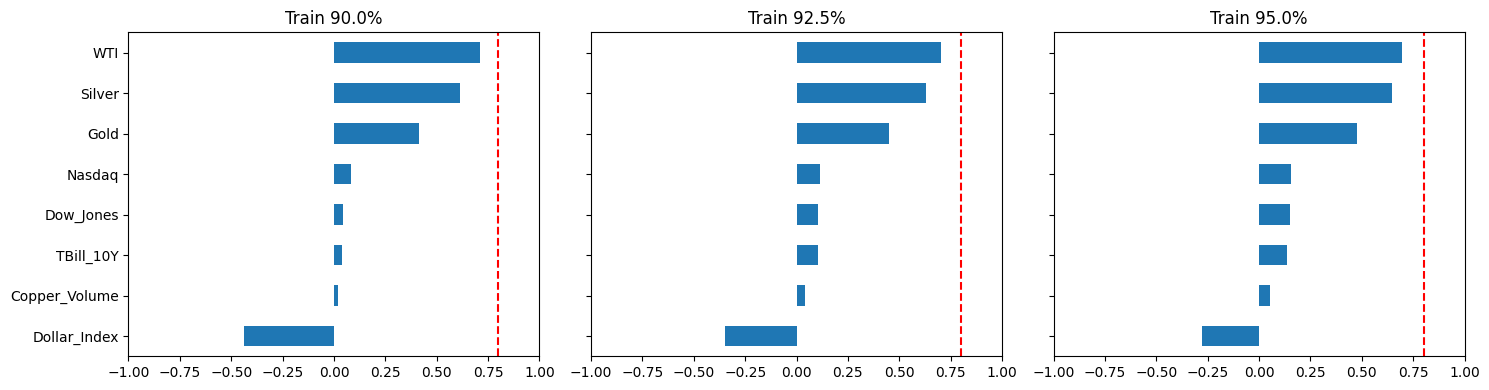

In [21]:
CANDIDATES = ['Dow_Jones','Nasdaq','Dollar_Index','TBill_10Y','Gold','Silver','WTI','Copper_Volume']

def get_split_context(ratio):
    split_row = int(len(raw)*ratio) # chia THEO NGÀY trước bất kỳ thống kê học nào
    val_start = int(split_row * .90)
    fit_raw = raw.iloc[:val_start]  # do not leak validation into SA search
    corr = fit_raw[CANDIDATES].corrwith(fit_raw['Copper'], method='spearman').sort_values(ascending=False)
    chosen = corr[corr > SPEARMAN_CUTOFF].index.tolist()
    if not chosen:
        chosen = corr.head(3).index.tolist()
        warnings.warn(f'{ratio:.1%}: không có Spearman > {SPEARMAN_CUTOFF}; fallback top 3 trên TRAIN!')
    xscaler = MinMaxScaler().fit(fit_raw[chosen].to_numpy())
    yscaler = MinMaxScaler().fit(fit_raw[['Copper']].to_numpy())
    # Transform cả tập bằng thông số học CHỈ từ TRAIN. Test có thể ra ngoài [0,1], là hợp lệ.
    x_all = xscaler.transform(raw[chosen].to_numpy()).astype('float32')
    y_all = yscaler.transform(raw[['Copper']].to_numpy()).astype('float32').reshape(-1)
    # test label index >= split_row; x của label t chỉ dùng các dòng t-SEQ_LENGTH...t-1
    # val nằm cuối TRAIN; split val theo TARGET index, không dựa vào window index
    assert val_start > SEQ_LENGTH
    def windows(label_start, label_end):
        X = np.stack([x_all[t-SEQ_LENGTH:t] for t in range(label_start, label_end)])
        y = y_all[label_start:label_end]
        dates = raw.index[label_start:label_end]
        return X, y, dates
    Xtr,ytr,dtr = windows(SEQ_LENGTH,val_start)
    Xva,yva,dva = windows(val_start,split_row)
    Xte,yte,dte = windows(split_row,len(raw))
    assert dtr.max() < dva.min() < dte.min()
    assert dte.min() == raw.index[split_row]
    assert Xtr.shape[-1] == len(chosen)
    return dict(ratio=ratio, corr=corr, chosen=chosen, scaler=yscaler,
                train=(Xtr,ytr,dtr), val=(Xva,yva,dva), test=(Xte,yte,dte), split=split_row)

contexts = [get_split_context(r) for r in TRAIN_RATIOS]
for ctx in contexts:
    print(f"train={ctx['ratio']:.1%} | features={ctx['chosen']} | "
          f"train/val/test = {[len(ctx[k][1]) for k in ['train','val','test']]}")
    display(ctx['corr'].rename('Spearman_vs_Copper_TRAIN').to_frame().T.round(3))
# Báo cáo Spearman tính lại cho toàn bộ 8 ứng viên; KHÔNG dùng test để chọn biến.
fig, axes = plt.subplots(1,3,figsize=(15,4),sharey=True)
for ax,ctx in zip(axes,contexts):
    ctx['corr'].sort_values().plot.barh(ax=ax)
    ax.axvline(.8,color='red',ls='--'); ax.set_title(f"Train {ctx['ratio']:.1%}"); ax.set_xlim(-1,1)
plt.tight_layout(); plt.show()

## 3. Kiến trúc & 3 mô hình

Hai lớp LSTM dùng `activation='tanh'`, `recurrent_activation='sigmoid'` (phù hợp công thức mô tả LSTM trong bài). Giữ Dense(32, relu) và Dropout(0.2), Dense(1, tanh) **chỉ là cấu hình thử nghiệm**. Bài báo Table 4 công bố `39/111`, `5e-5`, `batch=64`, `epochs=100`, `dropout=0.2`. Baseline 32/32 và lr=1e-3 do đồ án tự đặt. SA-LSTM cá nhân và SA-LSTM bài báo hiện trùng tham số. Các mô hình được fit riêng nhưng cùng seed để dễ so sánh.

In [22]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Cấu hình tác giả công bố tại Table 4, p.15 (Chen et al., 2023).
PAPER_SA = {'lr': 0.00005, 'units1': 39, 'units2': 111}
# Chỉ là mốc kết quả SA cũ của người dùng, KHÔNG dùng làm đầu vào cho SA mới.
OLD_USER_SA = {'lr': 0.00005, 'units1': 39, 'units2': 111}
# Baseline cố định do đồ án định nghĩa (không phải kiến trúc baseline được tác giả công bố).
BASELINE = {'lr': 0.001, 'units1': 32, 'units2': 32}
print('SA mới khởi tạo từ', SA_INIT, '| mốc bài báo:', PAPER_SA)

def build_lstm(n_features, hp):
    model = Sequential([
        Input(shape=(SEQ_LENGTH,n_features)),
        LSTM(int(hp['units1']), activation='tanh', recurrent_activation='sigmoid', return_sequences=True),
        LSTM(int(hp['units2']), activation='tanh', recurrent_activation='sigmoid'),
        Dense(32,activation='relu'), Dropout(0.2), Dense(1, activation='tanh')
    ])
    model.compile(optimizer=Adam(learning_rate=float(hp['lr'])),loss='mse')
    return model

def fit_and_evaluate(ctx,hp,name,epochs=EPOCHS):
    tf.keras.backend.clear_session(); gc.collect()
    tf.keras.utils.set_random_seed(SEED)
    Xtr,ytr,_=ctx['train']; Xva,yva,_=ctx['val']; Xte,yte,dte=ctx['test']
    net=build_lstm(Xtr.shape[-1],hp)
    history=net.fit(Xtr,ytr,validation_data=(Xva,yva),epochs=epochs,
                    batch_size=BATCH,shuffle=False,verbose=0)
    pred_scaled=net.predict(Xte,batch_size=BATCH,verbose=0)
    true=ctx['scaler'].inverse_transform(yte.reshape(-1,1)).reshape(-1)
    pred=ctx['scaler'].inverse_transform(pred_scaled).reshape(-1)
    out=dict(model=name,ratio=ctx['ratio'],features=', '.join(ctx['chosen']),
             MSE_scaled=mean_squared_error(yte,pred_scaled.reshape(-1)),
             MSE_USD2=mean_squared_error(true,pred),
             RMSE_USD=np.sqrt(mean_squared_error(true,pred)),
             MAE_USD=mean_absolute_error(true,pred),
             lr=hp['lr'],units1=hp['units1'],units2=hp['units2'],
             test_start=str(dte.min().date()),test_end=str(dte.max().date()),n_test=len(dte))
    return out,dict(date=dte,true=true,pred=pred,history=history.history),net

SA mới khởi tạo từ {'lr': 0.0005, 'units1': 15, 'units2': 30} | mốc bài báo: {'lr': 5e-05, 'units1': 39, 'units2': 111}


## 4. Chạy lại Simulated Annealing trên dữ liệu 2006–2026

`SA_MODE='rerun'` được **bật sẵn**. Bài báo khởi tạo từ LR=0.0005, neurons=15/30 (trang 10), và công bố kết quả LR=0.00005, neurons=39/111 (Table 4); **không được sao chép bộ kết quả cũ làm kết quả SA hiện tại**.

- Tối ưu *ba siêu tham số* (learning rate, số neuron LSTM tầng 1 và tầng 2) trên train/validation của từng tỷ lệ; **test không tham gia SA**.
- Mặc định thử 30 bước/tỷ lệ × 15 epochs để khả thi trên Kaggle; **đây là SA thực nghiệm rút gọn**, không phải tái hiện đầy đủ 650 scenarios của bài báo. Tăng `SA_STEPS` và `SA_TRIAL_EPOCHS` nếu cần độ tin cậy cao hơn. Sau SA, mỗi mô hình chính huấn luyện lại 100 epochs.
- SA dùng perturbation theo nhiệt độ, Metropolis acceptance, cooling 0.95; kiểm soát seed, lưu nhật ký ứng viên và hyperparameters tối ưu vào CSV. **Không đảm bảo** SA mới sẽ khác bộ 39/111 vì đó là kết quả tối ưu phụ thuộc dữ liệu.


In [23]:
from pathlib import Path

SA_DIR = Path('/kaggle/working') if Path('/kaggle/working').is_dir() else Path('.')

def sa_search(ctx, steps=SA_STEPS, trial_epochs=SA_TRIAL_EPOCHS,
              t_initial=SA_T0, cooling=SA_COOLING):
    Xtr, ytr, _ = ctx['train']
    Xva, yva, _ = ctx['val']
    # Seed theo ratio giúp mỗi phép thử tái lập và độc lập giữa các tỷ lệ.
    rng = np.random.default_rng(SEED + int(ctx['ratio'] * 10000))
    cache = {}

    def score(hp):
        key = (round(hp['lr'], 10), int(hp['units1']), int(hp['units2']))
        if key in cache:
            return cache[key]
        tf.keras.backend.clear_session()
        gc.collect()
        tf.keras.utils.set_random_seed(SEED)
        net = build_lstm(Xtr.shape[-1], hp)
        net.fit(Xtr, ytr, epochs=trial_epochs, batch_size=BATCH,
                shuffle=False, verbose=0)
        loss = float(net.evaluate(Xva, yva, verbose=0))
        del net
        gc.collect()
        if not np.isfinite(loss):
            loss = float('inf')
        cache[key] = loss
        return loss

    # Theo giá trị KHỞI TẠO của tác giả, không lấy nghiệm tối ưu 39/111 làm điểm xuất phát.
    current = dict(SA_INIT)
    current_loss = score(current)
    best, best_loss = dict(current), current_loss
    temp = float(t_initial)
    records = [dict(step=0, temperature=temp, candidate_mse=current_loss,
                    accepted=True, best_mse=best_loss, **current)]
    print(f"Ratio {ctx['ratio']:.1%}: initial val MSE={current_loss:.7f}")
    for step in range(1, steps + 1):
        # Tìm kiếm LR trên thang log; thay đổi số neurons theo T; giới hạn khả thi.
        cand = {
            'lr': float(np.clip(current['lr'] * np.exp(rng.uniform(-1, 1) * (0.5 + temp) * 2.0),
                                1e-6, 0.005)),
            'units1': int(np.clip(round(current['units1'] + rng.uniform(-1, 1) * (16 + 80*temp)), 8, 128)),
            'units2': int(np.clip(round(current['units2'] + rng.uniform(-1, 1) * (16 + 80*temp)), 8, 128)),
        }
        candidate_loss = score(cand)
        delta = candidate_loss - current_loss
        # Nhiệt độ làm giảm xác suất nhận nghiệm kém, scale theo loss ban đầu.
        loss_scale = max(records[0]['candidate_mse'], 1e-6)
        acceptance_probability = (1.0 if delta <= 0 else
                                  float(np.exp(-delta / max(temp * loss_scale, 1e-12))))
        accepted = bool(rng.random() < acceptance_probability)
        if accepted:
            current, current_loss = dict(cand), candidate_loss
        if candidate_loss < best_loss:
            best, best_loss = dict(cand), candidate_loss
        records.append(dict(step=step, temperature=temp, candidate_mse=candidate_loss,
                            accepted=accepted, best_mse=best_loss,
                            acceptance_probability=acceptance_probability, **cand))
        temp *= cooling
        print(f"SA [{ctx['ratio']:.1%}] {step:02d}/{steps} | val={candidate_loss:.7f} | best={best_loss:.7f}")
    return best, best_loss, pd.DataFrame(records)

SA_HP_BY_RATIO = {}
SA_HISTORY = {}
if SA_MODE == 'rerun':
    for ctx in contexts:
        ratio = ctx['ratio']
        hp, val_mse, history = sa_search(ctx)
        SA_HP_BY_RATIO[ratio] = hp
        SA_HISTORY[ratio] = history
        suffix = f"{ratio:.3f}".replace('.', '_')
        history.to_csv(SA_DIR / f'sa_history_ratio_{suffix}.csv', index=False)
        print(f"BEST SA ratio={ratio:.1%}: {hp}, validation MSE={val_mse:.7f}")
    sa_best = pd.DataFrame([dict(ratio=r, **hp) for r, hp in SA_HP_BY_RATIO.items()])
    sa_best.to_csv(SA_DIR / 'sa_best_hyperparameters_2006_2026.csv', index=False)
    display(sa_best)
elif SA_MODE == 'preset':
    # Chế độ debug: đối chiếu mốc SA cũ, KHÔNG được gọi là SA tìm lại trên dữ liệu mới.
    SA_HP_BY_RATIO = {ctx['ratio']: dict(OLD_USER_SA) for ctx in contexts}
else:
    raise ValueError("SA_MODE phải là 'rerun' hoặc 'preset'")
print('SA mode:', SA_MODE, '| best parameters:', SA_HP_BY_RATIO)


E0000 00:00:1794450405.823056      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794450415.682902      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Ratio 90.0%: initial val MSE=0.0246595


E0000 00:00:1794450426.358255      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


SA [90.0%] 01/30 | val=0.0183278 | best=0.0183278


E0000 00:00:1794450437.338588      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


SA [90.0%] 02/30 | val=0.0186162 | best=0.0183278


... (178 outputs left out)

E0000 00:00:1794451534.380990      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


SA [95.0%] 30/30 | val=0.0089166 | best=0.0068130
BEST SA ratio=95.0%: {'lr': 0.0004666597278878472, 'units1': 83, 'units2': 128}, validation MSE=0.0068130


,ratio,lr,units1,units2
0,0.900,0.000917,34,128
1,0.925,0.000904,88,114
2,0.950,0.000467,83,128


SA mode: rerun | best parameters: {0.9: {'lr': 0.0009173543319811961, 'units1': 34, 'units2': 128}, 0.925: {'lr': 0.0009038616067749657, 'units1': 88, 'units2': 114}, 0.95: {'lr': 0.0004666597278878472, 'units1': 83, 'units2': 128}}


In [24]:
results=[]; traces={}
for ctx in contexts:
    ratio=ctx['ratio']; print(f'\n=== TRAIN RATIO {ratio:.1%} ===')
    experiments = [
        ('LSTM baseline', BASELINE),
        ('SA-LSTM newly optimized ('+SA_MODE+')', SA_HP_BY_RATIO[ratio]),
        ('SA-LSTM paper (Table 4)', PAPER_SA),
    ]
    for name,hp in experiments:
        row,trace,net=fit_and_evaluate(ctx,hp,name)
        results.append(row); traces[(ratio,name)]=trace
        print(name,'MSE scaled=',round(row['MSE_scaled'],6),'MSE USD²=',round(row['MSE_USD2'],6))
        del net; gc.collect()
report=pd.DataFrame(results)
display(report.round(6))
path = '/kaggle/working/copper_lstm_comparison.csv' if os.path.isdir('/kaggle/working') else 'copper_lstm_comparison.csv'
report.to_csv(path,index=False)
print('Saved:', path)
print('Mô hình SA mới đã tìm trên validation; mô hình paper dùng thông số cố định công bố (Table 4).')


=== TRAIN RATIO 90.0% ===


E0000 00:00:1794451540.484194      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794451598.383923      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

LSTM baseline MSE scaled= 0.10012 MSE USD²= 1.356968


E0000 00:00:1794451604.620189      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794451662.869898      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

SA-LSTM newly optimized (rerun) MSE scaled= 0.082573 MSE USD²= 1.119148


E0000 00:00:1794451669.191531      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794451727.991478      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

... (11 outputs left out)

E0000 00:00:1794452067.662303      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1794452129.020656      50 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

SA-LSTM paper (Table 4) MSE scaled= 0.124552 MSE USD²= 1.688112


,model,ratio,features,MSE_scaled,MSE_USD2,RMSE_USD,MAE_USD,lr,units1,units2,test_start,test_end,n_test
0,LSTM baseline,0.900,"WTI, Silver, Gold",0.100120,1.356968,1.164890,0.910226,0.001000,32,32,2024-09-30,2026-10-30,524
1,SA-LSTM newly optimized (rerun),0.900,"WTI, Silver, Gold",0.082573,1.119148,1.057898,0.920322,0.000917,34,128,2024-09-30,2026-10-30,524
2,SA-LSTM paper (Table 4),0.900,"WTI, Silver, Gold",0.063139,0.855756,0.925071,0.724681,0.000050,39,111,2024-09-30,2026-10-30,524
3,LSTM baseline,0.925,"WTI, Silver, Gold",0.444900,6.029921,2.455590,2.355193,0.001000,32,32,2025-04-09,2026-10-30,393
4,SA-LSTM newly optimized (rerun),0.925,"WTI, Silver, Gold",0.138332,1.874875,1.369261,1.135210,0.000904,88,114,2025-04-09,2026-10-30,393
5,SA-LSTM paper (Table 4),0.925,"WTI, Silver, Gold",0.080009,1.084401,1.041346,0.849241,0.000050,39,111,2025-04-09,2026-10-30,393
6,LSTM baseline,0.950,"WTI, Silver, Gold",0.246383,3.339332,1.827384,1.753971,0.001000,32,32,2025-10-16,2026-10-30,262
7,SA-LSTM newly optimized (rerun),0.950,"WTI, Silver, Gold",0.184544,2.501205,1.581520,1.466081,0.000467,83,128,2025-10-16,2026-10-30,262
8,SA-LSTM paper (Table 4),0.950,"WTI, Silver, Gold",0.124552,1.688112,1.299274,1.194984,0.000050,39,111,2025-10-16,2026-10-30,262


Saved: /kaggle/working/copper_lstm_comparison.csv
Mô hình SA mới đã tìm trên validation; mô hình paper dùng thông số cố định công bố (Table 4).


## 5. Đánh giá 3 mô hình

Đánh giá riêng theo 3 tỷ lệ train/test 90/10, 92.5/7.5, 95/5; validation tách từ train. Mỗi mô hình 100 epochs. MSE trên dữ liệu đã chuẩn hóa không được đối chiếu trực tiếp với nghiên cứu 1990–2009 vì khác dữ liệu, tiền xử lý và cách chia. Khi `USER_SA == PAPER_SA` và cùng seed, hai đường dự đoán có thể chồng khít nhau.

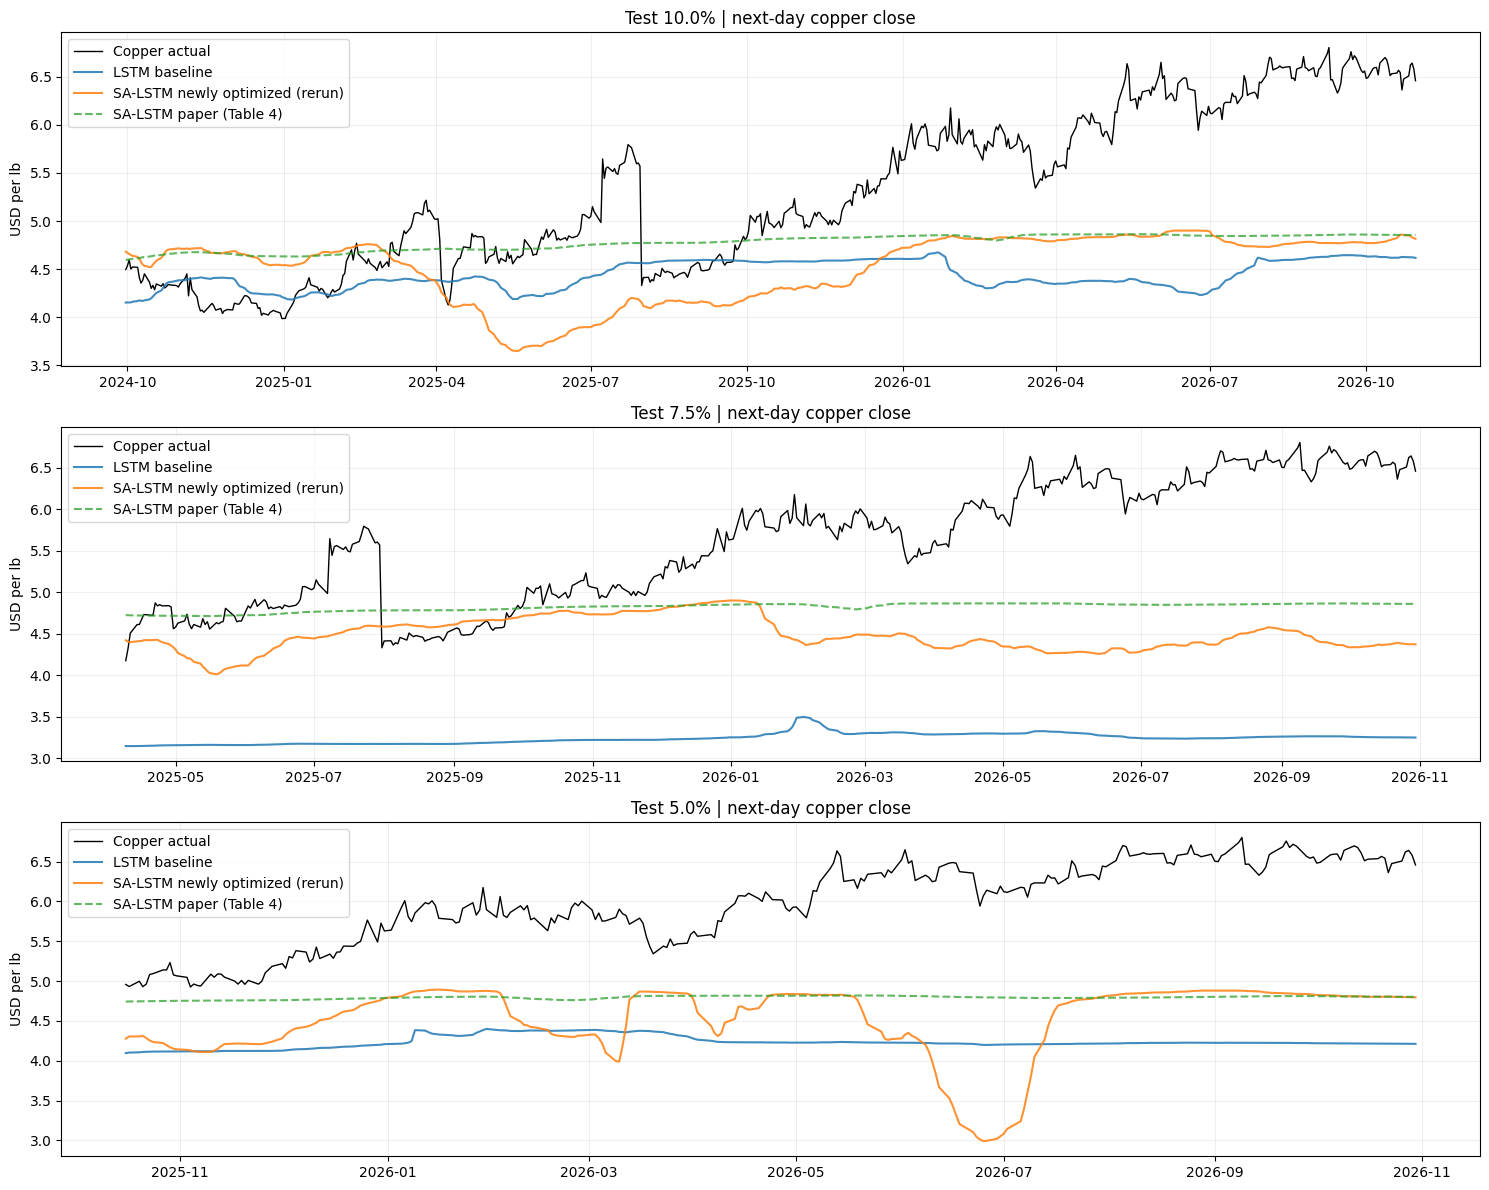

model,LSTM baseline,SA-LSTM newly optimized (rerun),SA-LSTM paper (Table 4)
ratio,,,
0.900,0.100120,0.082573,0.063139
0.925,0.444900,0.138332,0.080009
0.950,0.246383,0.184544,0.124552


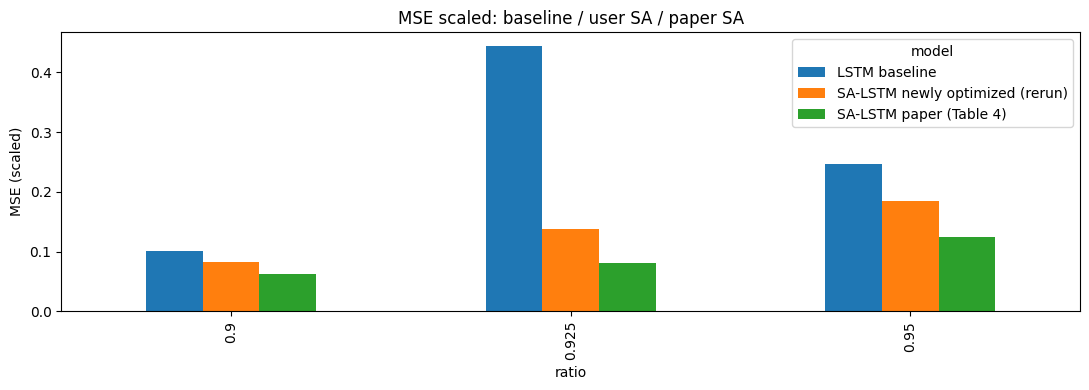

In [25]:
fig,axes=plt.subplots(3,1,figsize=(15,12))
for ax,ctx in zip(axes,contexts):
    ratio=ctx['ratio']
    names=['LSTM baseline','SA-LSTM newly optimized ('+SA_MODE+')','SA-LSTM paper (Table 4)']
    a,b,c=[traces[(ratio,name)] for name in names]
    ax.plot(a['date'],a['true'],label='Copper actual',color='black',linewidth=1)
    ax.plot(a['date'],a['pred'],label=names[0],alpha=.85)
    ax.plot(b['date'],b['pred'],label=names[1],alpha=.85)
    ax.plot(c['date'],c['pred'],label=names[2],alpha=.75,linestyle='--')
    ax.set(title=f'Test {1-ratio:.1%} | next-day copper close',ylabel='USD per lb'); ax.legend(); ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

pivot=report.pivot(index='ratio',columns='model',values='MSE_scaled')
display(pivot.round(6))
pivot.plot(kind='bar',figsize=(11,4),title='MSE scaled: baseline / user SA / paper SA')
plt.ylabel('MSE (scaled)'); plt.tight_layout(); plt.show()

## 6. Lịch sử tối ưu SA (chỉ validation)
Biểu đồ này dùng validation MSE (không dùng test), giúp báo cáo convergence của SA.


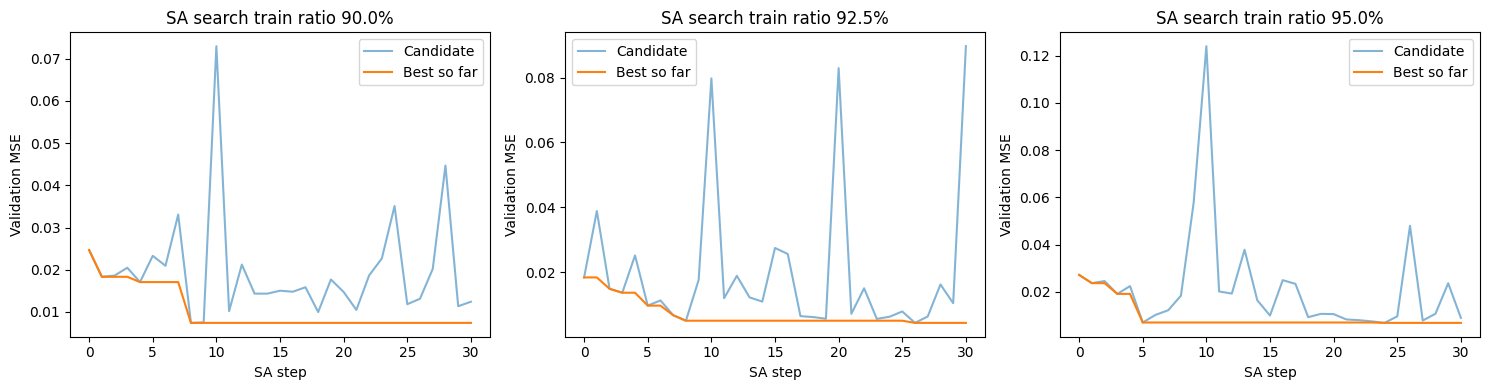

In [26]:
if SA_HISTORY:
    fig, axes = plt.subplots(1, len(SA_HISTORY), figsize=(15, 4), squeeze=False)
    for ax, (ratio, hist) in zip(axes[0], SA_HISTORY.items()):
        ax.plot(hist['step'], hist['candidate_mse'], alpha=.55, label='Candidate')
        ax.plot(hist['step'], hist['best_mse'], label='Best so far')
        ax.set(title=f'SA search train ratio {ratio:.1%}', xlabel='SA step', ylabel='Validation MSE')
        ax.legend()
    plt.tight_layout()
    plt.show()


## 7. Bảng đối chiếu nghiên cứu và giới hạn

| Nguồn | Phương pháp | Kết quả | Phạm vi |
|---|---|---|---|
| Chen et al. 2023 | SA-LSTM | MSE **0.00195 / 0.00190 / 0.00097** | 485 / 363 / 242 phiên kiểm tra; giai đoạn 1990–2009, nguồn Investing.com; cách chuẩn hóa không đủ chi tiết để khẳng định cùng thang đo |
| [26] Dehghani & Bogdanovic (2018) | BA | **Không có số MSE được Chen et al. công bố trong bảng so sánh trực tiếp** | Kết quả tham khảo từ tài liệu [26], **không chạy trên cùng bộ dữ liệu hiện tại** |
| [27] Astudillo et al. (2020) | SVR | **Không có số MSE được Chen et al. công bố trong bảng so sánh trực tiếp** | Kết quả tham khảo từ tài liệu [27], **không chạy trên cùng bộ dữ liệu hiện tại** |
| [28] Khoshalan et al. (2021) | ANFIS | **Không có số MSE được Chen et al. công bố trong bảng so sánh trực tiếp** | Kết quả tham khảo từ tài liệu [28], **không chạy trên cùng bộ dữ liệu hiện tại** |

**Không bịa số BA/SVR/ANFIS:** cần đọc trực tiếp [26]–[28] và chuẩn hóa metric trước khi bổ sung trị số; bài PDF Chen chỉ trích dẫn công trình chứ không cho bảng số liệu đó. Các hàng LSTM và SA-LSTM ở bảng phía trên mới là kết quả **chạy cùng dữ liệu 2006–2026**.

**Khác biệt với bài gốc:** Yahoo thay Investing; giai đoạn khác; lookback 30 do notebook gốc (không được nêu rõ trong bài); cách validation riêng để tránh data leakage; feature selection theo TRAIN thay vì tính toàn bộ 1990–2009. Vì vậy đây là *methodology replication on updated data*, không phải exact reproduction of published MSE.

**Tài liệu:** Chen, J. et al. (2023), *PLOS ONE* 18(10), e0285631, DOI 10.1371/journal.pone.0285631; [26] *Resources Policy* 55, 55–61; [27] *Applied Sciences* 10(19), 6648; [28] *Resources Policy* 73, 102239.